# 05 · 剩余库存可结转：动态规划

notebook 03 中，卖不掉的货在周末**作废**。普通门店里剩余的货留在仓库，下周还能卖。这样各周的决策就相互关联了：今天多订，下周就少订。

新增两项成本：
- **保管费** `h = 0.5` 元：每件在仓库多放一周的成本；
- **运费** `K` 元：每次订货的固定成本，与订多少件无关（来一趟车就要付钱）。

缺货成本仍为 `b = 6` 元/件（损失的利润）。

**范围：** 2017 年全年 52 周，从空仓库开始。

**步骤：**
1. 根据贝尔曼方程写出 DP，从最后一周往前逆序递推。
2. 没有运费（K = 0）：验证理论，DP 应该得到“每周补到 S”的简单策略。
3. 有运费（K = 200）：DP 得到 **(s, S)** 策略，订货次数更少、每次订更多。
4. 在全部 500 条序列上计算节省了多少。

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")
FIG = Path("../figures")

h, b = 0.5, 6.0          # 保管费和缺货成本，元/件
fc = pd.read_csv(DATA / "forecasts.csv", parse_dates=["week"])

# 规划期：2017 年全年 52 周
WEEKS = sorted(fc.loc[fc["split"] == "test", "week"].unique())
print("规划期:", pd.Timestamp(WEEKS[0]).date(), "→", pd.Timestamp(WEEKS[-1]).date(), f"（{len(WEEKS)} 周）")

规划期: 2017-01-02 → 2017-12-25 （52 周）


## 1. 单条序列的需求情景

与 notebook 04 相同：第 t 周的需求 = 方法 C 的预测 + 2016 年 52 个预测误差之一。库存按件计算，所以取整。

In [34]:
groups = {key: g.set_index("week") for key, g in fc.groupby(["store", "item"])}

def series(store, item):
    d = groups[(store, item)]
    v = d[d["split"] == "valid"]
    errors = (v["sales"] - v["pred_C"]).values           # 2016 年的 52 个误差
    t = d.loc[WEEKS]
    return t["pred_C"].values, t["sales"].values, errors

def scenarios(pred, errors):
    """T × 52 的矩阵：每周需求的可能取值。"""
    return np.maximum(0, np.round(pred[:, None] + errors[None, :])).astype(int)

pred, actual, errors = series(1, 1)
D = scenarios(pred, errors)
print("预测，前 12 周:", pred[:12].round().astype(int))
print("实际需求，前 12 周:", actual[:12])

预测，前 12 周: [112  88 119 116 112 116 141 102 132 129 145 163]
实际需求，前 12 周: [113 112 111 104 132 117 116 116 131 112 145 124]


## 2. 贝尔曼方程

**状态** `x`：周初的库存（件）。**决策** `y ≥ x`：补货到什么水平（`y = x` 表示不订货）。

先算**库存水平为 y 时的成本**：

`G_t(y) = 各情景平均 [ h·max(y−D, 0) + b·max(D−y, 0) + V_{t+1}(max(y−D, 0)) ]`

即：剩余的保管费 + 缺货损失 + 带着剩余库存进入下周后的最优未来成本。

再算**库存为 x 时的最优决策**：

`V_t(x) = min( G_t(x) ,  K + min_{y ≥ x} G_t(y) )`

第一项是**不订货**（保持 x），第二项是**订货**：付 K，并选择最好的水平 y。

从最后一周开始：`V_{T+1}(x) = 0`（规划期之后不计成本），然后依次计算第 T、T−1、…、1 周。

**例子：** K = 200，库存 x = 90。若 G(90) = 400，最优水平 y = 210 时 G(210) = 150，则订货：200 + 150 = 350 < 400，补到 210。若库存 150，G(150) = 300，则 200 + 150 = 350 > 300，不订货，运费不划算。

In [35]:
def solve_dp(D, K):
    """逆序递推。返回 policy[t][x]：周初库存为 x 时补货到的水平。"""
    T = D.shape[0]
    X = int(D.max() * 5) + 1                 # 考虑的最大库存（留足余量，避免碰到边界）
    y = np.arange(X)
    V_next = np.zeros(X)                     # V_{T+1}(x) = 0
    policy = [None] * T

    for t in range(T - 1, -1, -1):           # 从最后一周往前
        left = np.maximum(y[:, None] - D[t][None, :], 0)     # 各情景的剩余
        short = np.maximum(D[t][None, :] - y[:, None], 0)    # 各情景的缺货
        G = (h * left + b * short + V_next[np.minimum(left, X - 1)]).mean(axis=1)

        # 对每个 x：找 y ≥ x 中 G 最小的水平。
        # 思路：从右往左扫描，记住 G 最小的位置。易读但较慢的写法：
        #     best = X - 1
        #     for x in range(X - 1, -1, -1):
        #         if G[x] <= G[best]: best = x
        #         best_y[x] = best
        # 下面用 numpy 实现同样的步骤，不用循环，52 周也能很快算完。
        G_rev = G[::-1]
        is_new_min = G_rev <= np.minimum.accumulate(G_rev)
        last_min_pos = np.maximum.accumulate(np.where(is_new_min, np.arange(X), 0))
        best_y = (X - 1 - last_min_pos)[::-1]
        best_G = G[best_y]

        order = K + best_G < G                                # 订货是否划算
        policy[t] = np.where(order, best_y, y)
        V_next = np.where(order, K + best_G, G)               # 这是 V_t，在计算第 t−1 周时作为 V_{t+1}

    return policy

## 3. 没有运费（K = 0）：验证理论

运筹学理论：如果没有固定订货成本、成本是线性的，最优策略是每周**补货到水平 S**（基本库存策略），S 是需求在 `b / (b + h) = 6 / 6.5 ≈ 0.92` 水平上的分位数。这就是 CR 不同的报童模型。

验证 DP 是否得到同样的水平：

In [36]:
policy0 = solve_dp(D, K=0)
S_dp = np.array([p[0] for p in policy0])                       # 空仓库时 DP 补到的水平
S_formula = np.round(np.quantile(D, b / (b + h), axis=1)).astype(int)
print("DP，前 12 周:  ", S_dp[:12])
print("公式，前 12 周:", S_formula[:12])
print("完全相同:", np.array_equal(S_dp, S_formula))

DP，前 12 周:   [138 113 144 141 137 142 167 128 158 154 170 189]
公式，前 12 周: [138 113 144 141 137 142 167 128 158 154 170 189]
完全相同: True


两者相同，说明 DP 写法正确，同时用数值方法**验证了定理**：没有固定成本时，简单策略已经是最优的，不需要复杂的 DP。工具要根据问题来选择。

## 4. 有运费（K = 200）：(s, S) 策略

每次订货要付 200 元，每周都订太贵。DP 为每周找到两个数：
- **s**（订货点）：库存低于 s 时订货；
- **S**（订货上限）：订货到 S。

库存在 s 和 S 之间时不订货。这就是著名的 **(s, S) 策略**，Scarf 于 1960 年证明了它的最优性。

In [37]:
K = 200
policy = solve_dp(D, K)

def s_and_S(p):
    x = np.arange(len(p))
    ordering = p > x
    S = p[0]
    s = x[ordering].max() + 1 if ordering.any() else 0     # 不再订货的最小库存
    return s, S

sS = pd.DataFrame([s_and_S(p) for p in policy], columns=["s（低于此值订货）", "S（订货到）"],
                  index=[pd.Timestamp(w).date() for w in WEEKS])
sS["预测"] = pred.round().astype(int)
sS.head(12)          # 前 12 周；完整表格在变量 sS 中

,s（低于此值订货）,S（订货到）,预测
2017-01-02,91,327,112
2017-01-09,59,227,88
2017-01-16,92,356,119
2017-01-23,92,352,116
2017-01-30,84,249,112
2017-02-06,90,368,116
2017-02-13,117,385,141
2017-02-20,75,255,102
2017-02-27,104,417,132
2017-03-06,105,294,129


**策略图（第 1 周）：** 横轴为当前库存，纵轴为补货后的库存。
- K = 0：先是水平线（补到 S），再是对角线，即“每周都补到 S”；
- K = 200：对角线更早开始，库存在 s 和 S 之间时**不订货**。

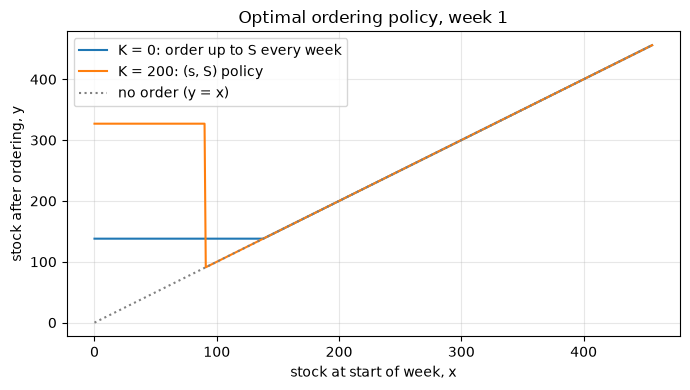

In [38]:
x = np.arange(len(policy[0]))
lim = int(sS.iloc[0, 1] * 1.4)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x[:lim], policy0[0][:lim], label="K = 0: order up to S every week")
ax.plot(x[:lim], policy[0][:lim], label=f"K = {K}: (s, S) policy")
ax.plot(x[:lim], x[:lim], color="gray", ls=":", label="no order (y = x)")
ax.set_xlabel("stock at start of week, x")
ax.set_ylabel("stock after ordering, y")
ax.set_title("Optimal ordering policy, week 1")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_policy_shape.png", dpi=150)
plt.show()

## 5. 用 2017 年的真实需求模拟

从空仓库开始，每周按策略行动：
- **DP (s, S)**：只有库存低于 s 时才订货；
- **每周补到 S**：不考虑运费的公式；
- **报童 CR = 0.67**：如同 notebook 03，假设剩余作废（对本情形是错误的模型）。

In [39]:
def simulate(order_rule, actual, K):
    x, cost, deliveries, path = 0, 0.0, 0, []
    for t in range(len(actual)):
        y = order_rule(t, x)
        if y > x:
            cost += K
            deliveries += 1
        cost += h * max(y - actual[t], 0) + b * max(actual[t] - y, 0)
        path.append((x, y))
        x = max(y - actual[t], 0)
    return cost, deliveries, path

def rules(D, K):
    pol = solve_dp(D, K)
    S92 = np.round(np.quantile(D, b / (b + h), axis=1))
    S67 = np.round(np.quantile(D, 2 / 3, axis=1))
    return {
        "DP (s, S)": lambda t, x: pol[t][min(x, len(pol[t]) - 1)],
        "每周补到 S": lambda t, x: max(x, S92[t]),
        "报童 CR = 0.67": lambda t, x: max(x, S67[t]),
    }

one = {name: simulate(rule, actual, K) for name, rule in rules(D, K).items()}
for name, (cost, n, _) in one.items():
    print(f"{name}: 成本 {cost:.0f} 元，订货 {n} 次")

DP (s, S): 成本 8260 元，订货 24 次
每周补到 S: 成本 11348 元，订货 52 次
报童 CR = 0.67: 成本 11717 元，订货 52 次


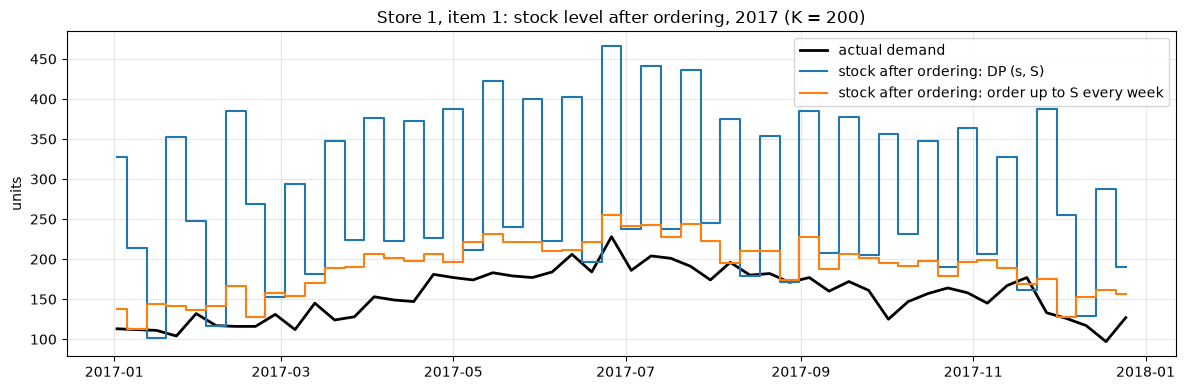

In [40]:
fig, ax = plt.subplots(figsize=(12, 4))
weeks = [pd.Timestamp(w) for w in WEEKS]
ax.plot(weeks, actual, color="black", lw=2, label="actual demand")
for name, label in [("DP (s, S)", "DP (s, S)"), ("每周补到 S", "order up to S every week")]:
    ys = [y for _, y in one[name][2]]
    ax.step(weeks, ys, where="mid", label=f"stock after ordering: {label}")
ax.set_ylabel("units")
ax.set_title(f"Store 1, item 1: stock level after ordering, 2017 (K = {K})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "05_stock_path.png", dpi=150)
plt.show()

## 6. 全部 500 条序列，不同运费

对每个“门店 × 商品”求解 DP，并在 52 周的真实需求上模拟。对 K = 0、100、200、500 各做一次。需要几分钟（500 条序列 × 4 种运费 × 52 周）。

In [41]:
rows = []
for K_ in [0, 100, 200, 500]:
    totals = {}
    for (store, item) in groups:
        p_, a_, e_ = series(store, item)
        D_ = scenarios(p_, e_)
        for name, rule in rules(D_, K_).items():
            c_, n_, _ = simulate(rule, a_, K_)
            totals.setdefault(name, [0.0, 0])
            totals[name][0] += c_
            totals[name][1] += n_
    for name, (c_, n_) in totals.items():
        rows.append({"K": K_, "policy": name, "cost_thousand": c_ / 1000,
                     "deliveries_per_series": n_ / len(groups)})

dp_res = pd.DataFrame(rows)
table = dp_res.pivot(index="K", columns="policy", values="cost_thousand").round(1)
table["DP 相对“每周补到 S”节省（%）"] = (100 * (1 - table["DP (s, S)"] / table["每周补到 S"])).round(1)
table

policy,"DP (s, S)",报童 CR = 0.67,每周补到 S,DP 相对“每周补到 S”节省（%）
K,,,,
0,776.5,915.0,777.6,0.1
100,3341.4,3515.0,3377.6,1.1
200,5526.0,6115.0,5977.6,7.6
500,9836.0,13915.0,13777.6,28.6


In [42]:
dp_res.pivot(index="K", columns="policy", values="deliveries_per_series").round(1)

policy,"DP (s, S)",报童 CR = 0.67,每周补到 S
K,,,
0,52.0,52.0,52.0
100,48.6,52.0,52.0
200,39.0,52.0,52.0
500,22.4,52.0,52.0


第二个表是每条序列每年的平均订货次数（最多 52 次）。运费越高，DP 订货越少。

## 7. 保存

In [43]:
dp_res.to_csv(DATA / "dp_results.csv", index=False)
print("已保存")

已保存


## 小结

- K = 0 时，DP 与公式 CR = b / (b + h) ≈ 0.92 的分位数完全相同，数值上验证了没有固定成本时“补到 S”策略是最优的。
- 有运费时，DP 得到 (s, S) 策略。K = 200 时比“每周补到 S”节省约 7.6%，每年订货次数从 52 次减到 39 次；K = 500 时节省约 28.6%。
- 剩余的货不作废、只付保管费，所以 CR 从 0.67 提高到 0.92。如果错误地使用“剩余作废”的报童模型，K = 0 时损失约高 18%。
- DP 从后往前计算，因为最后一周之后的未来是已知的（价值为 0）；算前一周时，未来的最优成本已经算好了（贝尔曼最优性原理）。